In [ ]:
import cv2
import os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import supervision as sv
import sys
import torch
from tqdm import tqdm
from trackers import ByteTrackTracker as ByteTrack

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(project_root)

from src.inference import PositionEstimatorPipeline
from notebook.preprocess_notebook import preprocess_notebook


xFormers not available
xFormers not available


## Get Start

In [ ]:
# config
cfg = {
    'inference':{
        'persondetection':{
            'detector_threshold': 0.8,
            'is_pose': True,
            'person_detector': 'RTDETR',
            'pose_estimator': 'ViTPose'
        },
        'input_padding_bbox': 2.0 # Based on this scale factor, crop the input image into a square by scaling the bbox's long side accordingly.
        },
    'positionestimation':{
        'pretrain_model': '../checkpoints/transformerhead.pt',
        'notebook': True,
        'DEVICE1': 0
    }
}
DEVICE = torch.device(f"cuda:{min(torch.cuda.device_count()-1, cfg['positionestimation']['DEVICE1'])}" if torch.cuda.is_available() else "cpu")

In [3]:
pipeline = PositionEstimatorPipeline(cfg=cfg, device=DEVICE)
# blow is notebook only
preprocess_notebook(pipeline)

The image processor of type `RTDetrImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 
Loading weights: 100%|██████████| 764/764 [00:00<00:00, 1050.33it/s, Materializing param=model.encoder_input_proj.2.1.weight]                                                
The image processor of type `VitPoseImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1026.27it/s, Materializing param=head.conv.weight]                                         


Head checkpoint ../checkpoints/transformerhead.pt is loaded.
Depth Anything V2 Checkpoint depth_anything_v2_vits.pth is not found.


## Image Inference

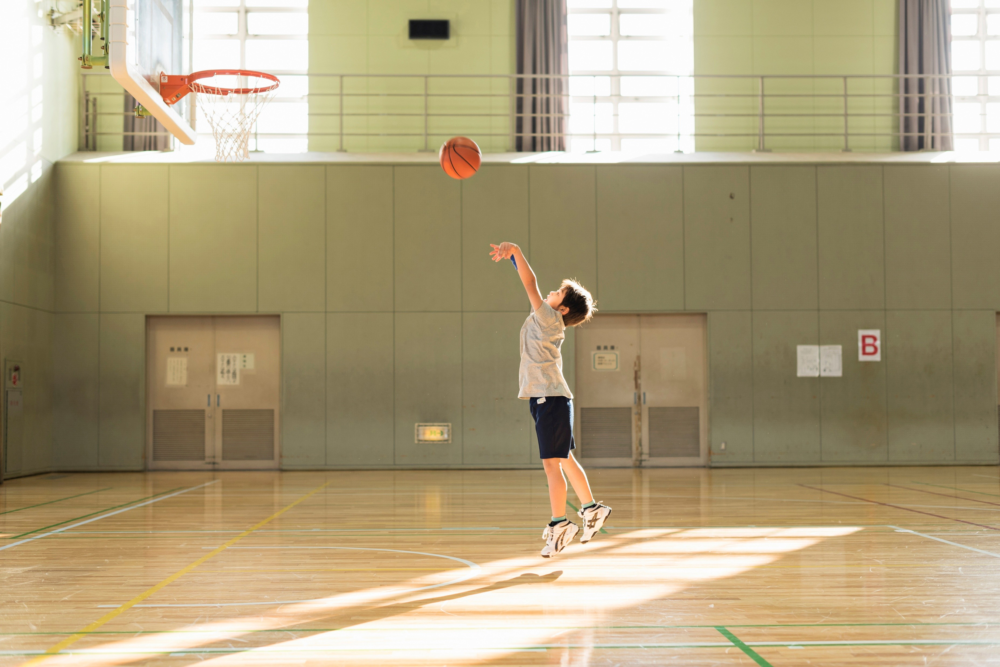

In [4]:
img = cv2.imread('../example/basket_example2.jpg')
Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

In [8]:
# inference
detect, kpts, pos, annotatedimg, heatmap = pipeline(img)


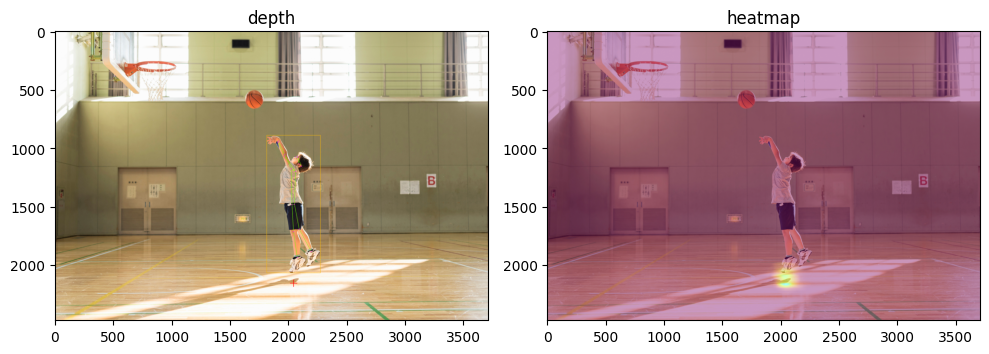

In [9]:
# show result
heatmap_view = cv2.addWeighted(img, 1 - 0.4, (heatmap*255).astype(np.uint8), 0.6, 0)
heatmap_view = cv2.cvtColor(heatmap_view, cv2.COLOR_RGB2BGR)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# show
# 1枚目
im1 = axes[0].imshow(cv2.cvtColor(annotatedimg, cv2.COLOR_BGR2RGB))
axes[0].set_title("depth")

# 2枚目
im2 = axes[1].imshow(heatmap_view)
axes[1].set_title("heatmap")

plt.tight_layout()
plt.show()

## Video Inference

In [7]:
video_path = "../example/jump1.mp4"

In [13]:
tracker = ByteTrack()
label_annotator = sv.LabelAnnotator()
cap = cv2.VideoCapture(video_path)

results = []
if not cap.isOpened():
    raise ValueError(f"Failed to open the video: {video_path}")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

for frame_idx in tqdm(range(total_frames), desc=f"Infering {os.path.basename(video_path)}"):
    ret, frame = cap.read()
    if not ret:
        break
    detect, kpt, pos, annotatedframe, heatmap = pipeline(frame)
    if detect is not None:
        detect = tracker.update(detect)
        annotatedframe = label_annotator.annotate(annotatedframe, detect, labels=detect.tracker_id)
    heatmap_view = cv2.addWeighted(frame, 1 - 0.4, (heatmap*255).astype(np.uint8), 0.6, 0)
    frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
    heatmap_view = cv2.cvtColor(heatmap_view, cv2.COLOR_RGB2BGR)

    result = {
        "frame": frame,
        "detect": detect,
        "keypoints": kpt,
        "pos": pos,
        "annotatedframe": annotatedframe,
        "heatmap":  heatmap
    }
    results.append(result)


Infering jump1.mp4: 100%|██████████| 122/122 [04:45<00:00,  2.34s/it]


In [ ]:
# show result
frame_idx = 0
if frame_idx < 0 or len(results) <= frame_idx:
    raise ValueError(f"frame index {frame_idx} is invalid:")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# show
# 1枚目
im1 = axes[0].imshow(results[frame_idx]["frame"])
axes[0].set_title("depth")

# 2枚目
im2 = axes[1].imshow(results[frame_idx]["heatmap"])
axes[1].set_title("heatmap")

plt.tight_layout()
plt.show()